## Exploratory Data Analysis (METABRIC Dataset)

**Goals:**
1. Load and understand the shape/types of the data.
2. Identify missing values and categorical vs. continuous features.
3. Explore basic univariate distributions.
4. Formulate initial hypotheses for clustering and dimensionality reduction.

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Set display options for large datasets
pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')

### 1. Data Loading & Initial Inspection

In [35]:
# Load the dataset
df = pd.read_csv('METABRIC_RNA_Mutation.csv', low_memory=False)

print(f"Dataset Shape: {df.shape}")
display(df.head())

Dataset Shape: (1904, 693)


,patient_id,age_at_diagnosis,type_of_breast_surgery,cancer_type,cancer_type_detailed,cellularity,chemotherapy,pam50_+_claudin-low_subtype,cohort,er_status_measured_by_ihc,er_status,neoplasm_histologic_grade,her2_status_measured_by_snp6,her2_status,tumor_other_histologic_subtype,hormone_therapy,inferred_menopausal_state,integrative_cluster,primary_tumor_laterality,lymph_nodes_examined_positive,mutation_count,nottingham_prognostic_index,oncotree_code,overall_survival_months,overall_survival,...,foxo1_mut,nt5e_mut,ccnd3_mut,nr3c1_mut,prkg1_mut,tbl1xr1_mut,frmd3_mut,smad2_mut,sgcd_mut,spaca1_mut,rasgef1b_mut,hist1h2bc_mut,nr2f1_mut,klrg1_mut,mbl2_mut,mtap_mut,ppp2cb_mut,smarcd1_mut,nras_mut,ndfip1_mut,hras_mut,prps2_mut,smarcb1_mut,stmn2_mut,siah1_mut
0,0,75.65,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,NaN,0,claudin-low,1.0,Positve,Positive,3.0,NEUTRAL,Negative,Ductal/NST,1,Post,4ER+,Right,10.0,NaN,6.044,IDC,140.500000,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2,43.19,BREAST CONSERVING,Breast Cancer,Breast Invasive Ductal Carcinoma,High,0,LumA,1.0,Positve,Positive,3.0,NEUTRAL,Negative,Ductal/NST,1,Pre,4ER+,Right,0.0,2.0,4.020,IDC,84.633333,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,5,48.87,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,High,1,LumB,1.0,Positve,Positive,2.0,NEUTRAL,Negative,Ductal/NST,1,Pre,3,Right,1.0,2.0,4.030,IDC,163.700000,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,6,47.68,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,Moderate,1,LumB,1.0,Positve,Positive,2.0,NEUTRAL,Negative,Mixed,1,Pre,9,Right,3.0,1.0,4.050,MDLC,164.933333,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,8,76.97,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,High,1,LumB,1.0,Positve,Positive,3.0,NEUTRAL,Negative,Mixed,1,Post,9,Right,8.0,2.0,6.080,MDLC,41.366667,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [36]:
# separate numerical and categorical columns for analysis
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print(f"Number of numerical columns: {len(numerical_cols)}")
print(f"Number of categorical columns: {len(categorical_cols)}")

# let's look at a few examples of each
print("\nSample Numerical Columns:", numerical_cols[:10])
print("\nSample Categorical Columns:", categorical_cols[:10])

Number of numerical columns: 503
Number of categorical columns: 190

Sample Numerical Columns: ['patient_id', 'age_at_diagnosis', 'chemotherapy', 'cohort', 'neoplasm_histologic_grade', 'hormone_therapy', 'lymph_nodes_examined_positive', 'mutation_count', 'nottingham_prognostic_index', 'overall_survival_months']

Sample Categorical Columns: ['type_of_breast_surgery', 'cancer_type', 'cancer_type_detailed', 'cellularity', 'pam50_+_claudin-low_subtype', 'er_status_measured_by_ihc', 'er_status', 'her2_status_measured_by_snp6', 'her2_status', 'tumor_other_histologic_subtype']


### 2. Missing Values Analysis
Understanding which features have the most missing data will dictate our cleaning strategy (imputation vs. dropping).

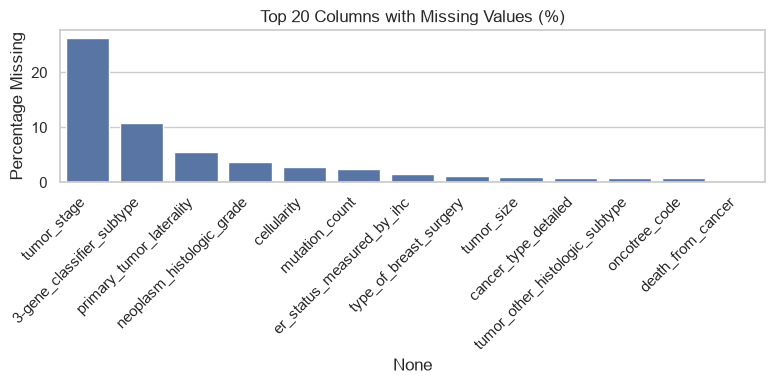

In [37]:
# Calculate percentage of missing values per column
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_percent = missing_percent[missing_percent > 0].sort_values(ascending=False)

# Plot top 20 columns with missing values
if not missing_percent.empty:
    plt.figure(figsize=(8, 4))
    sns.barplot(x=missing_percent.head(20).index, y=missing_percent.head(20).values)
    plt.xticks(rotation=45, ha='right')
    plt.title('Top 20 Columns with Missing Values (%)')
    plt.ylabel('Percentage Missing')
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found!")

### 3. Data Cleaning and preprocessing

In [ ]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Drop columns with excessive missing data (> 40%)
threshold = 0.2
missing_fraction = df.isnull().mean()
cols_to_drop = missing_fraction[missing_fraction > threshold].index
df_cleaned = df.drop(columns=cols_to_drop)

print(f"Dropped {len(cols_to_drop)} columns due to >20% missing data.")

# Separate features (X) and target (y)
# Adjust 'target_col' if you are predicting something else (e.g., 'overall_survival_months')
target_col = 'overall_survival'
X = df_cleaned.drop(columns=[target_col])
y = df_cleaned[target_col]

# Identify numerical and categorical columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object', 'category']).columns

# Build preprocessing pipelines
# Numerical: Impute missing values with the median, then scale to mean=0, variance=1
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# One hot encode
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# combine pipelines into a ColumnTransformer
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

# Fit and transform the feature matrix
X_processed = preprocessor.fit_transform(X)

# Reconstruct a Pandas DataFrame for downstream EDA and Feature Selection
# Retrieve new column names post-encoding
cat_feature_names = preprocessor.named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(cat_cols)
all_feature_names = list(num_cols) + list(cat_feature_names)

X_processed_df = pd.DataFrame(X_processed, columns=all_feature_names, index=X.index)

print(f"Original shape: {df.shape}")
print(f"Processed shape: {X_processed_df.shape}")
display(X_processed_df.head())

Dropped 1 columns due to >20% missing data.
Original shape: (1904, 693)
Processed shape: (1904, 8499)


,patient_id,age_at_diagnosis,chemotherapy,cohort,neoplasm_histologic_grade,hormone_therapy,lymph_nodes_examined_positive,mutation_count,nottingham_prognostic_index,overall_survival_months,radio_therapy,tumor_size,brca1,brca2,palb2,pten,tp53,atm,cdh1,chek2,nbn,nf1,stk11,bard1,mlh1,...,smarcd1_mut_M366T,smarcd1_mut_N84S,smarcd1_mut_P78R,nras_mut_0,nras_mut_D108N,nras_mut_G12S,nras_mut_T124A,ndfip1_mut_0,ndfip1_mut_A50T,ndfip1_mut_N68S,ndfip1_mut_X51_splice,hras_mut_0,hras_mut_N86T,hras_mut_Q61R,prps2_mut_0,prps2_mut_G255R,prps2_mut_I159F,smarcb1_mut_0,smarcb1_mut_D159N,smarcb1_mut_I28L,stmn2_mut_0,stmn2_mut_N145K,stmn2_mut_R156H,siah1_mut_0,siah1_mut_T249A
0,-1.663366,1.122359,-0.512445,-1.338368,0.867685,0.788547,1.960788,-0.169839,1.757557,0.201518,0.821330,-0.278813,-1.399001,-0.573800,-1.6217,1.452401,0.350399,1.151701,0.034798,0.1266,-0.836099,-0.857800,-0.429399,-1.120101,-0.484399,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,-1.662518,-1.379317,-0.512445,-1.338368,0.867685,0.788547,-0.490841,-0.917810,-0.011378,-0.530544,0.821330,-1.074529,-1.380001,0.277701,-1.2154,0.529601,-0.013601,-0.265900,1.359398,0.7961,0.541900,-2.605901,0.512000,0.439000,1.226601,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,-1.661245,-0.941562,1.951430,-1.338368,-0.676308,0.788547,-0.245678,-0.917810,-0.002638,0.505525,-1.217538,-0.742981,0.067001,-0.842600,0.2114,-0.332599,0.514099,-0.080300,1.139798,0.4187,-0.402999,-1.130500,0.236200,-0.172101,-1.790999,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,-1.660821,-1.033275,1.951430,-1.338368,-0.676308,0.788547,0.244648,-1.167134,0.014841,0.521686,0.821330,-0.079884,0.674401,-0.542800,-1.6592,0.636901,1.670799,-0.888000,1.249098,-1.1889,-0.417399,-0.616499,1.007800,-0.401001,-1.390499,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,-1.659973,1.224091,1.951430,-1.338368,0.867685,0.788547,1.470462,-0.917810,1.789021,-1.097499,0.821330,0.914762,1.293202,-0.903900,-0.7219,0.216801,0.348399,0.389700,0.913098,0.9356,0.767500,-0.293999,-0.296099,0.632000,-0.358199,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


### 4. Target Definition & Clinical Overview
Before looking at gene expression, let's look at the clinical attributes (e.g., survival status, cancer subtype, age). These will likely be our 'target' variables for color-coding our Dash plots.

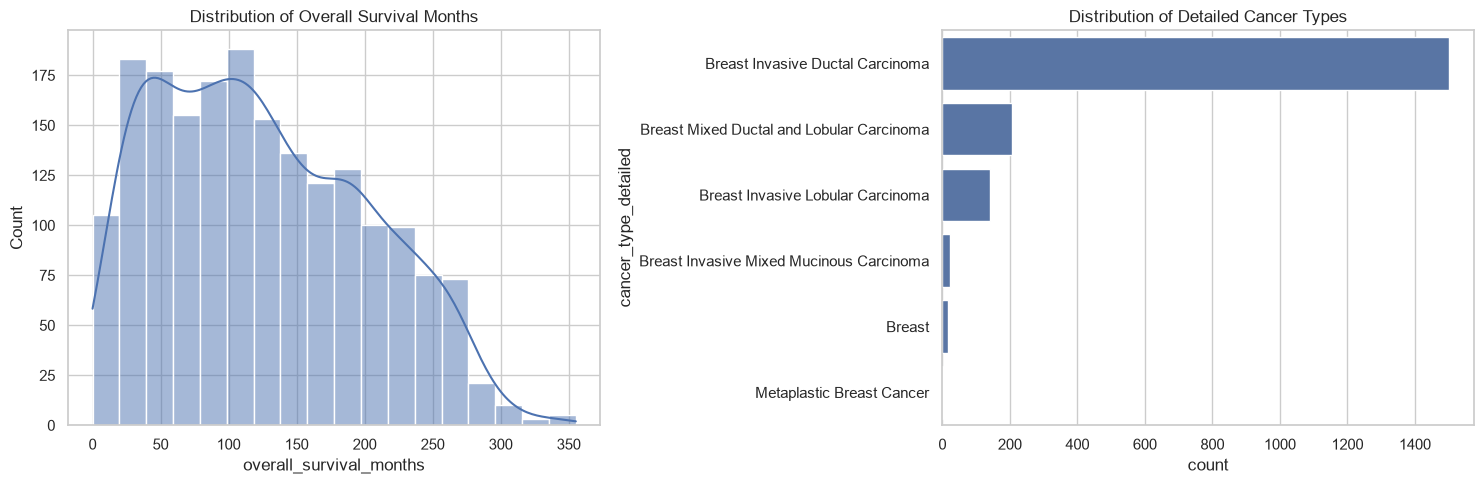

In [39]:
# let's examine the distribution of Patient Survival Status and Cancer Subtype
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Survival Status (we will use 'overall_survival_months' for numerical, and need to find the exact categorical column for death status)
sns.histplot(data=df, x='overall_survival_months', kde=True, ax=axes[0])
axes[0].set_title('Distribution of Overall Survival Months')

# sssuming there is a 'cancer_type_detailed' column based on standard METABRIC data
if 'cancer_type_detailed' in df.columns:
    sns.countplot(data=df, y='cancer_type_detailed', order=df['cancer_type_detailed'].value_counts().index, ax=axes[1])
    axes[1].set_title('Distribution of Detailed Cancer Types')

plt.tight_layout()
plt.show()

### 5. Target Definition


In [40]:
import plotly.express as px
import plotly.graph_objects as go
import plotly.figure_factory as ff
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from umap import UMAP
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler

# Define your ground-truth target for coloring (e.g., cancer type or survival status)
target_col = 'overall_survival' 
hover_cols = ['patient_id', 'age_at_diagnosis', 'cancer_type_detailed']

In [41]:
# Cell 2: Prototype EDA Distributions (Histogram & Violin)
def plot_feature_distribution(df, feature, n_bins=30):
    # Overlayed Histogram
    fig_hist = px.histogram(
        df, x=feature, color=target_col, 
        nbins=n_bins, barmode='overlay',
        title=f'{feature} Distribution by {target_col}',
        hover_data=hover_cols
    )
    # Customize hovertemplate to prove understanding of precise hover data
    fig_hist.update_traces(
        hovertemplate="<b>%{customdata[0]}</b><br>Value: %{x}<br>Age: %{customdata[1]}<br>Type: %{customdata[2]}<extra></extra>"
    )
    fig_hist.show()

    # Violin Plot for separability
    fig_violin = px.violin(
        df, y=feature, color=target_col, box=True, points="all",
        title=f'{feature} Separability',
        hover_data=hover_cols
    )
    fig_violin.show()

# Test the prototype
plot_feature_distribution(df, 'mutation_count', n_bins=50)

### 6. Feature Relationships & Selection

In [ ]:
# cell 3: Prototyping Heatmaps & Scatter Matrix
# select a subset of numerical features for testing
features = numerical_cols[:10] 
X = df[features].fillna(0)

# Pearson Correlation Heatmap (Diverging scale)
corr_matrix = X.corr().round(2)
fig_corr = ff.create_annotated_heatmap(
    z=corr_matrix.values, x=list(corr_matrix.columns), y=list(corr_matrix.index),
    colorscale='RdBu', zmin=-1, zmax=1, showscale=True
)
fig_corr.update_layout(title='Pearson Correlation (RdBu)')
fig_corr.show()

# Mutual Information Heatmap (Sequential scale)
mi_scores = mutual_info_classif(X, df[target_col].fillna(0))
# Reshape for heatmap visualization against the target
fig_mi = px.imshow(
    [mi_scores], x=features, y=['Mutual Info'], text_auto=True, color_continuous_scale='YlGnBu',
    title='Mutual Information with Target'
)
fig_mi.show()

# Interactive Scatter Matrix
fig_scatter = px.scatter_matrix(
    df, dimensions=features[:4], color=target_col,
    hover_data=['patient_id'],
    title="Scatter Matrix (Use Plotly Lasso Tool to select points)"
)
fig_scatter.update_traces(diagonal_visible=False)
fig_scatter.show()

### 7. Dimensionality Reduction & Clustering

In [43]:
# Dimensionality Reduction (Linear & Non-Linear) and Clustering
# standardize data first
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Dimensionality Reduction
# Linear DR
pca = PCA(n_components=2)
df['PCA_1'], df['PCA_2'] = pca.fit_transform(X_scaled).T

# Non-Linear DR
tsne = TSNE(n_components=2, random_state=42)
df['tSNE_1'], df['tSNE_2'] = tsne.fit_transform(X_scaled).T

# KMeans
kmeans = KMeans(n_clusters=3, random_state=42)
df['Cluster_KMeans'] = kmeans.fit_predict(X_scaled).astype(str)

# Hierarchical (Agglomerative)
hierarchical = AgglomerativeClustering(n_clusters=3)
df['Cluster_Hierarchical'] = hierarchical.fit_predict(X_scaled).astype(str)

# Density-Based (DBSCAN)
dbscan = DBSCAN(eps=0.5, min_samples=5)
df['Cluster_DBSCAN'] = dbscan.fit_predict(X_scaled).astype(str)

# Visualization
# plotting PCA colored by K-Means clusters
fig_dr = px.scatter(
    df, x='PCA_1', y='PCA_2', color='Cluster_KMeans',
    hover_data=hover_cols,
    title="PCA Projection colored by K-Means Clusters"
)
fig_dr.show()

# plotting t-SNE colored by Ground Truth
fig_tsne = px.scatter(
    df, x='tSNE_1', y='tSNE_2', color=target_col,
    hover_data=hover_cols + ['Cluster_KMeans', 'Cluster_DBSCAN'],
    title="t-SNE Projection colored by Actual Survival Status"
)
fig_tsne.show()